# Exercise 3 — Spaceship Titanic

Goal: turn a messy real-world CSV (missing values, mixed types, wildly skewed spending columns) into a clean numeric matrix that's safe to feed into a neural network with `tanh` hidden layers, **without leaking information from the test set into training.**

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SPEND_COLS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
NUM_COLS = ["Age"] + SPEND_COLS + ["TotalSpend"]
CAT_COLS = ["HomePlanet", "CryoSleep", "Destination", "VIP"]
DROP_COLS = ["PassengerId", "Name", "Cabin"]

rng = np.random.default_rng(42)
df = pd.read_csv("../../../../../data/SpaceshipTitanic/train.csv")
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## A — Look at the data first
Before touching anything: what's the target balance, what's missing, and how skewed are the spending columns? This drives every decision below.

In [2]:
df["Transported"].value_counts(normalize=True)

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64

In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).query("missing_count > 0").sort_values("missing_count", ascending=False)

,missing_count,missing_pct
CryoSleep,217,2.50
ShoppingMall,208,2.39
VIP,203,2.34
HomePlanet,201,2.31
Name,200,2.30
Cabin,199,2.29
VRDeck,188,2.16
FoodCourt,183,2.11
Spa,183,2.11
Destination,182,2.09


Every column has ~2-2.5% missing — nothing catastrophic, but every column needs a strategy.

In [4]:
df[SPEND_COLS].agg(["mean", "median", "max"]).T

,mean,median,max
RoomService,224.687617,0.0,14327.0
FoodCourt,458.077203,0.0,29813.0
ShoppingMall,173.729169,0.0,23492.0
Spa,311.138778,0.0,22408.0
VRDeck,304.854791,0.0,24133.0


Mean >> median for every spending column (median is literally 0). That's the signature of a right-skewed distribution: most passengers spend nothing, a few spend thousands. Standard scaling on raw values like this would be dominated by those outliers — that's why we log-transform before scaling (see part C).

## B — Split BEFORE touching anything else
This is the most important ordering decision in the whole exercise. If we imputed missing values or fit a scaler on the *full* dataset and then split, the test set's own statistics (its median, its mean/std) would have quietly influenced what the "training" transformers learned. That's data leakage — it makes test performance look better than it would be on truly unseen data. So: split first, fit every transformer only on the train fold, and just `.transform()` the test fold.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["Transported"], random_state=42)
print("Train shape:", train_df.shape, "Test shape:", test_df.shape)
print(train_df["Transported"].value_counts(normalize=True))
print(test_df["Transported"].value_counts(normalize=True))

Train shape: (6954, 14) Test shape: (1739, 14)
Transported
True     0.503595
False    0.496405
Name: proportion, dtype: float64
Transported
True     0.503738
False    0.496262
Name: proportion, dtype: float64


Both splits keep almost exactly the same ~50/50 target balance — that's what `stratify` guarantees.

## Feature engineering
`TotalSpend` sums the five spending columns (a single number for "how much did this passenger spend overall"). We drop `PassengerId` and `Name` (pure identifiers, no predictive signal) and `Cabin` (would need its own deck/side encoding, not required here).

In [6]:
def engineer(frame):
    frame = frame.copy()
    frame["TotalSpend"] = frame[SPEND_COLS].sum(axis=1, skipna=True)
    return frame.drop(columns=DROP_COLS)

train_fe = engineer(train_df)
test_fe = engineer(test_df)

y_train = train_fe.pop("Transported").astype(int)
y_test = test_fe.pop("Transported").astype(int)

## C — Preprocessing
**Log transform first.** `log1p(x) = log(1+x)` handles the zeros gracefully (log1p(0) = 0) while compressing the long tail of big spenders, so a later z-score isn't dominated by a handful of extreme values.

In [7]:
log_cols = SPEND_COLS + ["TotalSpend"]
foodcourt_before = train_fe["FoodCourt"].dropna().copy()

for frame in (train_fe, test_fe):
    for col in log_cols:
        frame[col] = np.log1p(frame[col].clip(lower=0))

foodcourt_after = train_fe["FoodCourt"].dropna().copy()

**Figure 6** — before/after, so we can actually see the log transform doing its job.

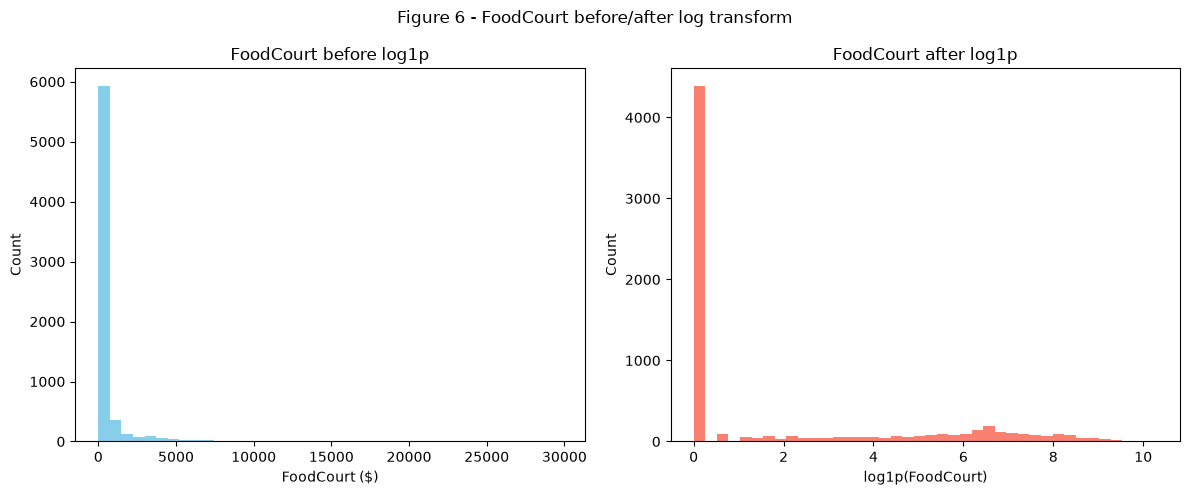

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(foodcourt_before, bins=40, color="skyblue")
axes[0].set_title("FoodCourt before log1p"); axes[0].set_xlabel("FoodCourt ($)"); axes[0].set_ylabel("Count")
axes[1].hist(foodcourt_after, bins=40, color="salmon")
axes[1].set_title("FoodCourt after log1p"); axes[1].set_xlabel("log1p(FoodCourt)"); axes[1].set_ylabel("Count")
fig.suptitle("Figure 6 - FoodCourt before/after log transform")
fig.tight_layout()
plt.show()

**Imputation + encoding + scaling**, all wrapped in a `ColumnTransformer` so it's guaranteed to be fit only on train and only ever `.transform()`-ed on test:

- Numeric columns: fill missing with the **train median**, then `StandardScaler` (mean 0, std 1).
- Categorical columns: fill missing with the **train mode**, then one-hot encode with `handle_unknown="ignore"` — so a category that only ever appears in test doesn't crash the encoder, it just gets an all-zeros row instead.

In [9]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", num_pipeline, NUM_COLS),
    ("cat", cat_pipeline, CAT_COLS),
])

X_train = preprocessor.fit_transform(train_fe)
X_test = preprocessor.transform(test_fe)
print("Train matrix:", X_train.shape, "Test matrix:", X_test.shape)

Train matrix: (6954, 17) Test matrix: (1739, 17)


## D — Verify it actually worked
Check there are no NaNs left, and that the scaled values sit in a range that won't saturate a `tanh` activation for most inputs.

In [10]:
print("Remaining NaNs in X_train:", np.isnan(X_train).sum())
print(f"Train range: [{X_train.min():.4f}, {X_train.max():.4f}]")
print(f"Test range:  [{X_test.min():.4f}, {X_test.max():.4f}]")

Remaining NaNs in X_train: 0
Train range: [-1.9961, 3.5080]
Test range:  [-1.9961, 3.3687]


## Takeaway
Standardization doesn't force values into exactly `[-1, 1]` the way min-max scaling would, but after log-compressing the spending columns first, almost everything lands within about ±3.5 — a stable range for `tanh`. The single decision that matters most here is the **log transform**: skip it, and the z-scores would be dominated by a few extreme spenders, saturating `tanh` for everyone else and leaving the network with almost no gradient to learn from.